# Task 2: Vehicle Crashworthiness Design


In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt


## NSGA-II experiment

A fixed seed makes the run reproducible.


In [5]:
crash_problem = CrashworthinessDesign()
CRASH_SEED = 2026
CRASH_POP_SIZE = 100
CRASH_MAX_GEN = 500
np.random.seed(CRASH_SEED)
crash_optimizer = NSGA2(pop_size=CRASH_POP_SIZE)
start_time = time.perf_counter()
crash_x, crash_f = crash_optimizer.run(crash_problem, max_gen=CRASH_MAX_GEN)
crash_runtime_seconds = time.perf_counter() - start_time
print(f'Seed={CRASH_SEED}, population={CRASH_POP_SIZE}, max_gen={CRASH_MAX_GEN}')
print(f'Elapsed time: {crash_runtime_seconds:.1f} s')


Seed=2026, population=100, max_gen=500
Elapsed time: 511.5 s


In [6]:
assert crash_x.shape == (CRASH_POP_SIZE, crash_problem.n_var)
assert crash_f.shape == (CRASH_POP_SIZE, crash_problem.n_obj)
assert np.isfinite(crash_x).all() and np.isfinite(crash_f).all()
assert np.all(crash_x >= crash_problem.lower)
assert np.all(crash_x <= crash_problem.upper)
np.testing.assert_allclose(crash_problem.evaluate(crash_x), crash_f, rtol=1e-12, atol=1e-12)
dominates = (np.all(crash_f[:, None, :] <= crash_f[None, :, :], axis=2)
             & np.any(crash_f[:, None, :] < crash_f[None, :, :], axis=2))
crash_nondominated = ~dominates.any(axis=0)
distinct_count = len(np.unique(crash_x, axis=0))
print(f'Distinct designs: {distinct_count}/{CRASH_POP_SIZE}')
print(f'Non-dominated in final population: {crash_nondominated.sum()}/{CRASH_POP_SIZE}')
for label, values in zip(('f1 weight', 'f2 acceleration', 'f3 intrusion'), crash_f.T):
    print(f'{label}: min={values.min():.6g}, median={np.median(values):.6g}, max={values.max():.6g}')


Distinct designs: 98/100
Non-dominated in final population: 100/100
f1 weight: min=1661.71, median=1676.2, max=1695.2
f2 acceleration: min=6.1428, median=7.7457, max=10.753
f3 intrusion: min=0.0394, median=0.0879051, max=0.264


## Final population in objective space

The pairwise views make sparsely sampled regions easier to see.


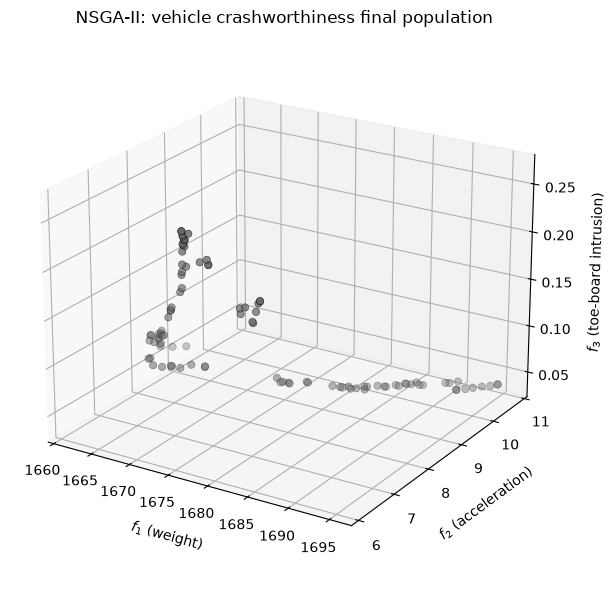

In [7]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(crash_f[:, 0], crash_f[:, 1], crash_f[:, 2],
           s=28, c='0.40', edgecolors='black', linewidths=0.35, alpha=0.9)
ax.set_xlabel(r'$f_1$ (weight)', labelpad=8)
ax.set_ylabel(r'$f_2$ (acceleration)', labelpad=8)
ax.set_zlabel(r'$f_3$ (toe-board intrusion)', labelpad=8)
ax.set_title('NSGA-II: vehicle crashworthiness final population')
ax.view_init(elev=22, azim=-58)
fig.tight_layout()
plt.show()


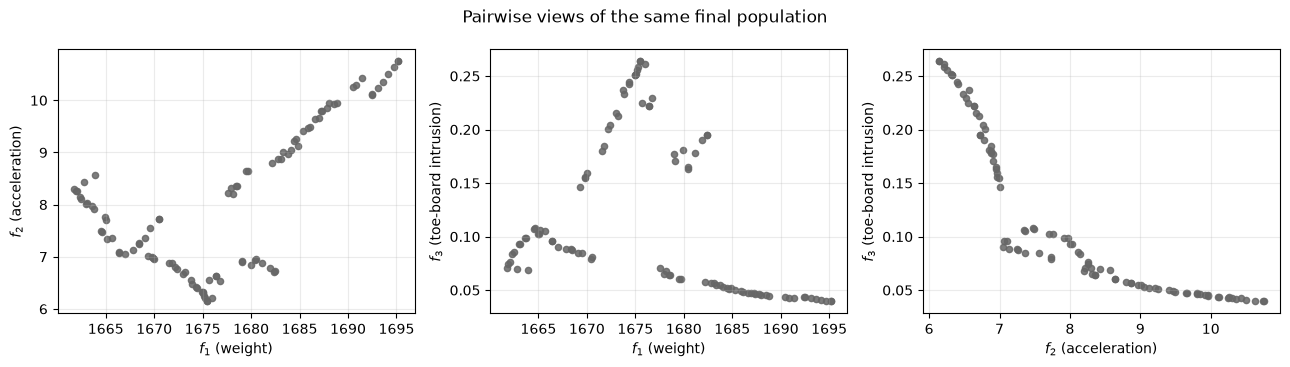

In [8]:
pairs = ((0, 1), (0, 2), (1, 2))
labels = (r'$f_1$ (weight)', r'$f_2$ (acceleration)',
          r'$f_3$ (toe-board intrusion)')
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
for ax, (i, j) in zip(axes, pairs):
    ax.scatter(crash_f[:, i], crash_f[:, j], s=20, c='0.40', alpha=0.85)
    ax.set_xlabel(labels[i])
    ax.set_ylabel(labels[j])
    ax.grid(alpha=0.25)
fig.suptitle('Pairwise views of the same final population')
fig.tight_layout()
plt.show()


## Results and discussion

With seed 2026, population size 100 and `max_gen=500`, the run produced 100 solutions (98 distinct). The objective-space plots show several branches with gaps and clusters. Designs with lower toe-board intrusion can have greater weight or acceleration, showing trade-offs among the three objectives.

The five thickness variables map nonlinearly to three objectives. NSGA-II's crowding distance spreads solutions within sampled regions, while a population of 100 and a per-variable mutation probability of 0.05 may leave other regions sparsely explored. To improve coverage, test a larger population or stronger mutation (higher mutation probability or lower polynomial-mutation distribution index). Compare coverage and spacing over several seeds using similar numbers of objective evaluations.
